# **Practical 1**

In [2]:
import pandas as pd
import numpy as np
import seaborn as sns

import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    accuracy_score,
    precision_score,
    recall_score,                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                        f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)



In [3]:
iris = load_iris()

X = iris.data
Y = iris.target

In [4]:
#displaying the dataset

df = pd.DataFrame(X, columns= iris.feature_names)

df['target'] = Y

df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


In [5]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   target             150 non-null    int64  
dtypes: float64(4), int64(1)
memory usage: 6.0 KB
None


In [6]:
print(df['target'].value_counts())

target
0    50
1    50
2    50
Name: count, dtype: int64


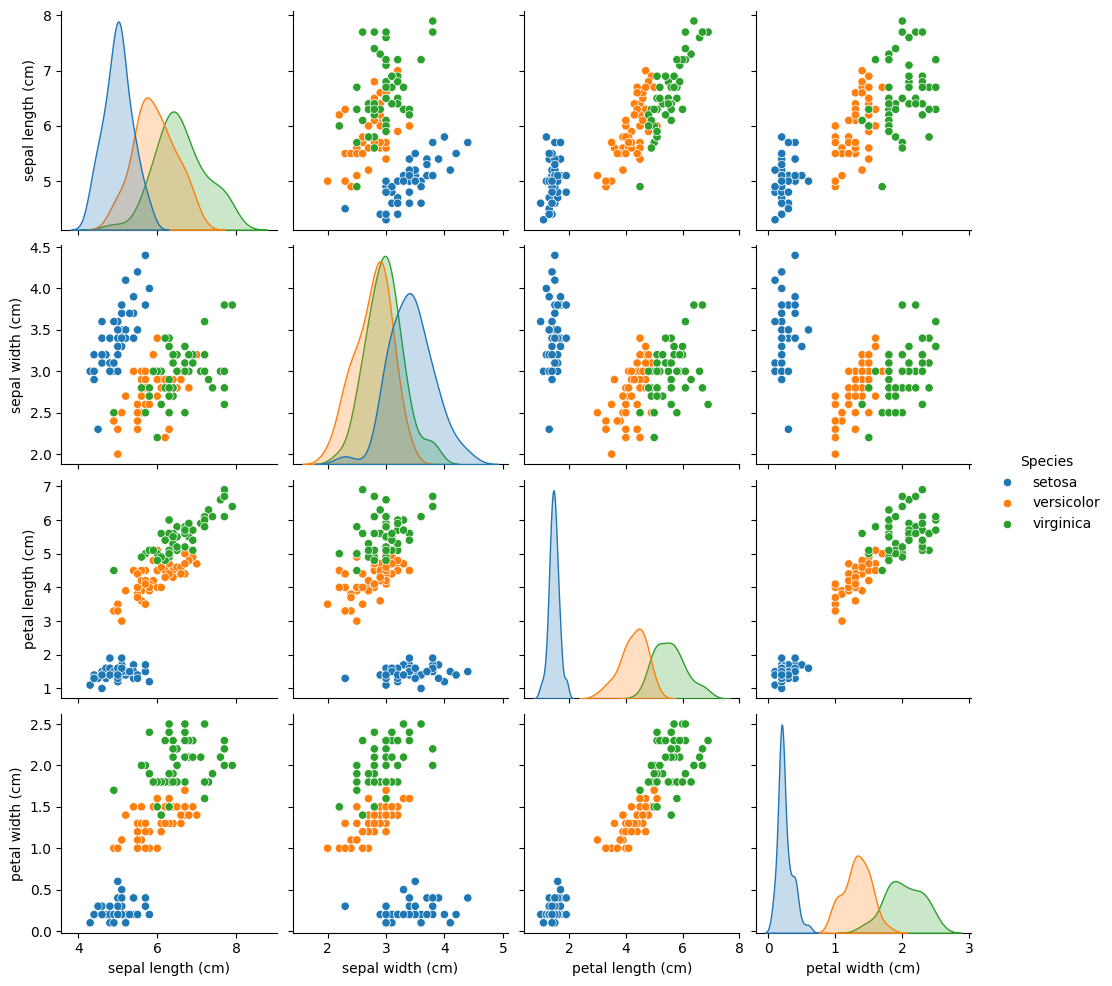

In [7]:
sns.pairplot(
    pd.DataFrame(
        X,
        columns=iris.feature_names
    ).assign(
        Species=pd.Categorical.from_codes(
            Y, iris.target_names
        )
    ),
    hue="Species"
)

plt.show()

In [8]:
X_train, X_test, Y_train, Y_test = train_test_split(
    X,
    Y,
    test_size=0.20,
    random_state=42,
    stratify=Y
)

In [9]:
print('Training samples:', X_train.shape[0])
print('Testing sample:', X_test.shape[0])


Training samples: 120
Testing sample: 30


In [10]:
model = GaussianNB()

In [11]:
model.fit(X_train, Y_train)

GaussianNB()

In [12]:
y_pred = model.predict(X_test)

In [13]:
print("Predicted values:")
print(y_pred)

print("\nActual values:")
print(Y_test)

Predicted values:
[0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 2 0 2 1 2 2 2 1 0 2 0]

Actual values:
[0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 2 0 2 1 2 2 1 1 0 2 0]


In [14]:
accuracy = accuracy_score(Y_test, y_pred)

print("Accuracy:", accuracy)
print("Accuracy (%):", accuracy * 100)

Accuracy: 0.9666666666666667
Accuracy (%): 96.66666666666667


In [15]:
#confusion matrix

cm = confusion_matrix(Y_test, y_pred)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[10  0  0]
 [ 0  9  1]
 [ 0  0 10]]


### **Practical 2**

## **Regression Models (Practicals 2 - 5)**

In [17]:
# Common Imports & Setup for Regression Tasks
import numpy as np
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.metrics import mean_squared_error, r2_score

# Setup synthetic continuous data for regression tasks
np.random.seed(42)
X_reg = np.random.rand(100, 3) * 10
y_reg = 3 * X_reg[:, 0] + 1.5 * X_reg[:, 1]**2 - 2 * X_reg[:, 2] + np.random.randn(100) * 2

X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(X_reg, y_reg, test_size=0.2, random_state=42)

def evaluate_regression_model(name, model, X_train, X_test, y_train, y_test, cv_folds=5):
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    mse = mean_squared_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)

    kf = KFold(n_splits=cv_folds, shuffle=True, random_state=42)
    cv_scores = cross_val_score(model, np.vstack((X_train, X_test)), np.concatenate((y_train, y_test)), cv=kf, scoring='neg_mean_squared_error')
    cv_mse_mean = -cv_scores.mean()

    print(f"=== {name} ===")
    print(f"Test MSE: {mse:.4f}")
    print(f"Test R2 Score: {r2:.4f}")
    print(f"{cv_folds}-Fold CV Mean MSE: {cv_mse_mean:.4f}\n")

In [18]:
# 2. Simple Linear Regression
from sklearn.linear_model import LinearRegression

evaluate_regression_model(
    "2. Simple Linear Regression (Single Feature)",
    LinearRegression(),
    X_train_r[:, [0]], X_test_r[:, [0]], y_train_r, y_test_r
)

=== 2. Simple Linear Regression (Single Feature) ===
Test MSE: 2147.3485
Test R2 Score: 0.0492
5-Fold CV Mean MSE: 2408.1246



In [19]:
# 3. Multiple Linear Regression
evaluate_regression_model(
    "3. Multiple Linear Regression",
    LinearRegression(),
    X_train_r, X_test_r, y_train_r, y_test_r
)

=== 3. Multiple Linear Regression ===
Test MSE: 148.6510
Test R2 Score: 0.9342
5-Fold CV Mean MSE: 140.1363



In [20]:
# 4. Polynomial Regression (Degree 2)
from sklearn.preprocessing import PolynomialFeatures

poly = PolynomialFeatures(degree=2)
X_train_poly = poly.fit_transform(X_train_r)
X_test_poly = poly.transform(X_test_r)

evaluate_regression_model(
    "4. Polynomial Regression (Degree 2)",
    LinearRegression(),
    X_train_poly, X_test_poly, y_train_r, y_test_r
)

=== 4. Polynomial Regression (Degree 2) ===
Test MSE: 8.4243
Test R2 Score: 0.9963
5-Fold CV Mean MSE: 4.2820



In [21]:
# 5. Lasso and Ridge Regression
from sklearn.linear_model import Lasso, Ridge

evaluate_regression_model(
    "5a. Lasso Regression",
    Lasso(alpha=0.1),
    X_train_r, X_test_r, y_train_r, y_test_r
)

evaluate_regression_model(
    "5b. Ridge Regression",
    Ridge(alpha=1.0),
    X_train_r, X_test_r, y_train_r, y_test_r
)

=== 5a. Lasso Regression ===
Test MSE: 148.7345
Test R2 Score: 0.9341
5-Fold CV Mean MSE: 140.1820

=== 5b. Ridge Regression ===
Test MSE: 148.5664
Test R2 Score: 0.9342
5-Fold CV Mean MSE: 140.1849



### **Visualizing Regression Model Performance**
We will plot the actual vs. predicted values for each regression model to visualize the fit quality.

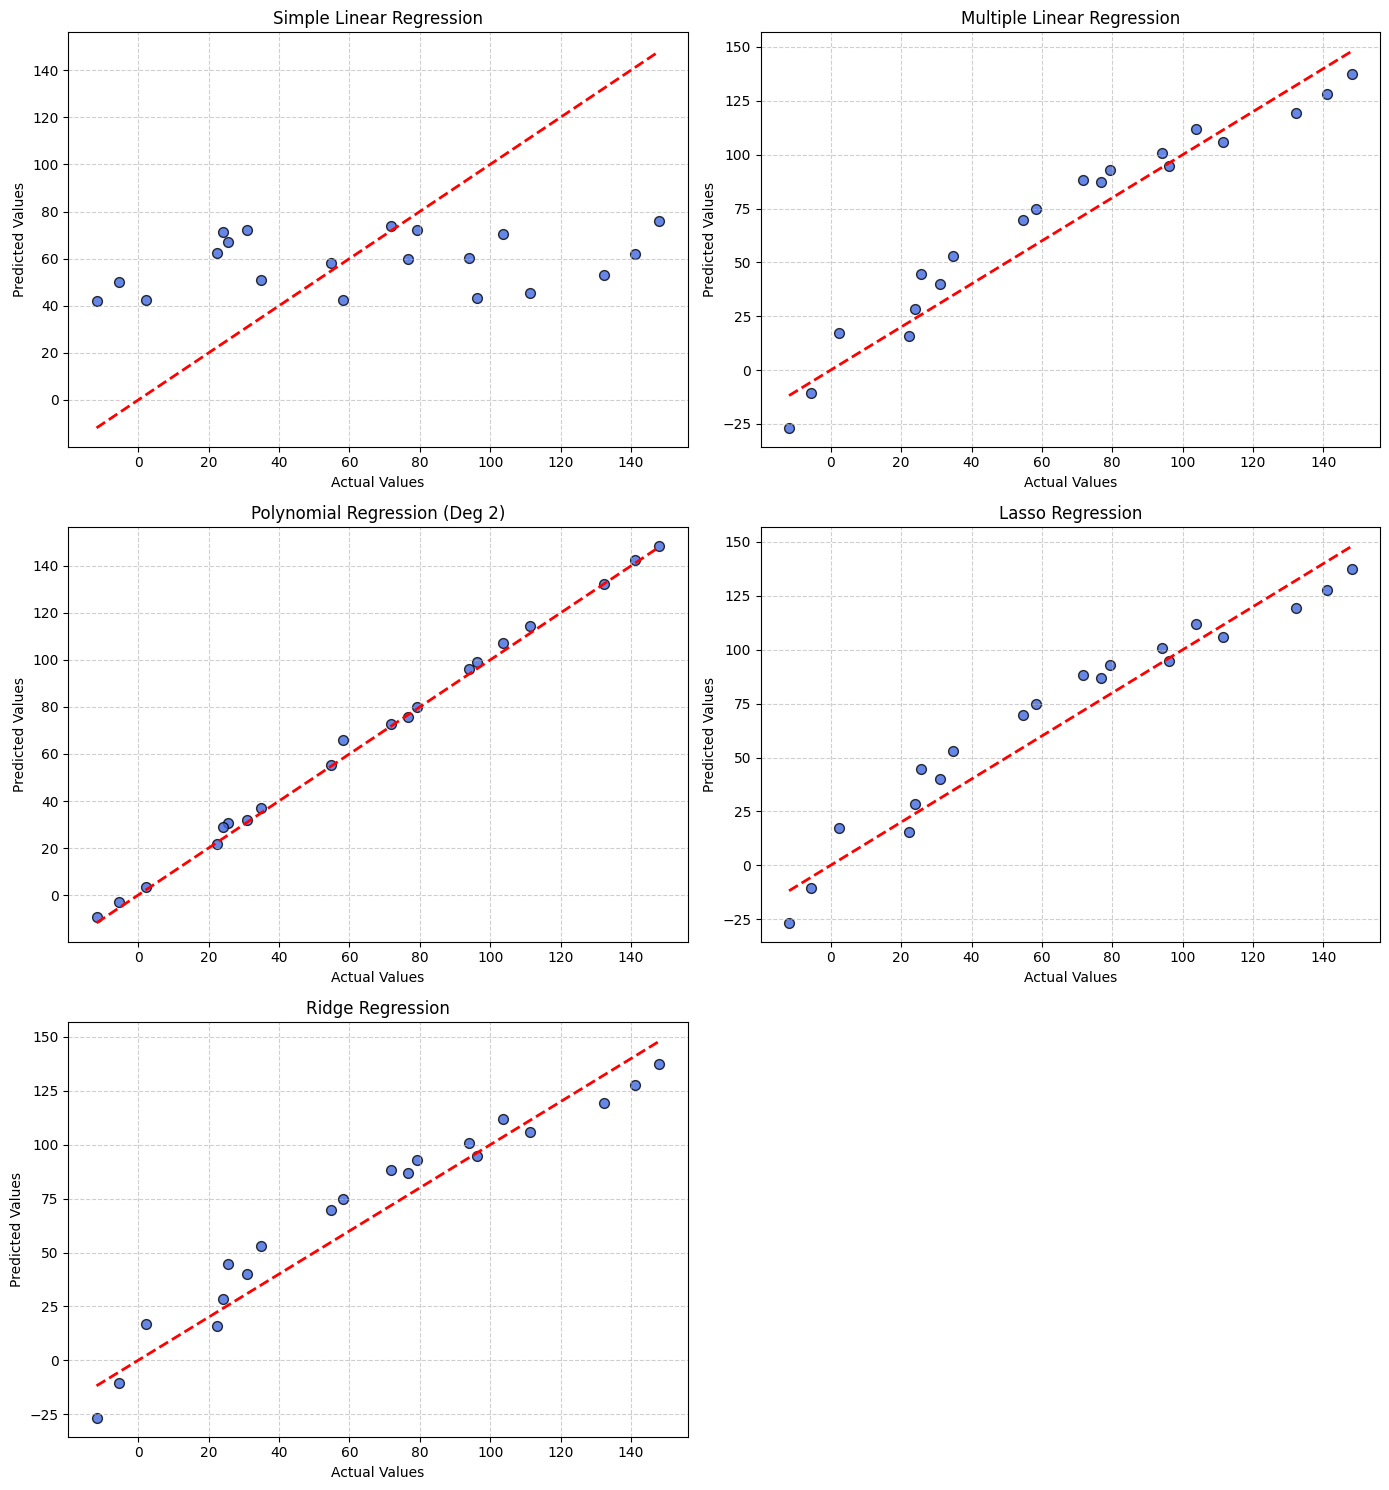

In [30]:
import matplotlib.pyplot as plt

# Dictionary of models to quickly predict and plot
reg_models = {
    "Simple Linear Regression": (LinearRegression(), X_train_r[:, [0]], X_test_r[:, [0]]),
    "Multiple Linear Regression": (LinearRegression(), X_train_r, X_test_r),
    "Polynomial Regression (Deg 2)": (LinearRegression(), X_train_poly, X_test_poly),
    "Lasso Regression": (Lasso(alpha=0.1), X_train_r, X_test_r),
    "Ridge Regression": (Ridge(alpha=1.0), X_train_r, X_test_r)
}

fig, axes = plt.subplots(3, 2, figsize=(14, 15))
axes = axes.ravel()

for idx, (name, (model, X_tr, X_te)) in enumerate(reg_models.items()):
    model.fit(X_tr, y_train_r)
    preds = model.predict(X_te)

    ax = axes[idx]
    ax.scatter(y_test_r, preds, color='royalblue', edgecolors='k', alpha=0.8, s=50)
    ax.plot([y_test_r.min(), y_test_r.max()], [y_test_r.min(), y_test_r.max()], 'r--', lw=2)
    ax.set_title(f"{name}")
    ax.set_xlabel("Actual Values")
    ax.set_ylabel("Predicted Values")
    ax.grid(True, linestyle='--', alpha=0.6)

# Turn off the empty subplot
fig.delaxes(axes[-1])
plt.tight_layout()
plt.show()

## **Classification Models (Practicals 6 - 10)**

In [22]:
# Common Setup for Classification Tasks (Using Iris Dataset)
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import accuracy_score, confusion_matrix, recall_score, f1_score, roc_auc_score

def evaluate_classification_model(name, model, X_train, X_test, y_train, y_test, cv_folds=5):
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    skf = StratifiedKFold(n_splits=cv_folds, shuffle=True, random_state=42)
    cv_scores = cross_val_score(model, np.vstack((X_train, X_test)), np.concatenate((y_train, y_test)), cv=skf, scoring='accuracy')
    cv_acc_mean = cv_scores.mean()

    cm = confusion_matrix(y_test, y_pred)
    accuracy = accuracy_score(y_test, y_pred)
    error = 1 - accuracy
    recall = recall_score(y_test, y_pred, average='macro')
    f1 = f1_score(y_test, y_pred, average='macro')

    n_classes = len(np.unique(y_test))
    specificities = []
    tps, tns, fps, fns = [], [], [], []
    for i in range(n_classes):
        tp = cm[i, i]
        fn = sum(cm[i, :]) - tp
        fp = sum(cm[:, i]) - tp
        tn = sum(sum(cm)) - tp - fn - fp

        tps.append(tp)
        fns.append(fn)
        fps.append(fp)
        tns.append(tn)

        specificity = tn / (tn + fp) if (tn + fp) > 0 else 0
        specificities.append(specificity)

    mean_specificity = np.mean(specificities)

    try:
        if hasattr(model, "predict_proba"):
            y_prob = model.predict_proba(X_test)
            auc = roc_auc_score(y_test, y_prob, multi_class='ovr')
        else:
            auc = "N/A (No probability estimates)"
    except Exception:
        auc = "N/A"

    print(f"=== {name} ===")
    print(f"Accuracy: {accuracy:.4f} | Error Rate: {error:.4f}")
    print(f"Mean TP: {np.mean(tps):.1f} | Mean TN: {np.mean(tns):.1f} | Mean FP: {np.mean(fps):.1f} | Mean FN: {np.mean(fns):.1f}")
    print(f"Recall (Sensitivity): {recall:.4f} | Specificity: {mean_specificity:.4f} | F1-Score: {f1:.4f}")
    print(f"AUC Score: {auc}")
    print(f"{cv_folds}-Fold CV Mean Accuracy: {cv_acc_mean:.4f}\n")

In [23]:
# 6. Logistic Regression
from sklearn.linear_model import LogisticRegression

evaluate_classification_model(
    "6. Logistic Regression",
    LogisticRegression(max_iter=200),
    X_train, X_test, Y_train, Y_test
)

=== 6. Logistic Regression ===
Accuracy: 0.9667 | Error Rate: 0.0333
Mean TP: 9.7 | Mean TN: 19.7 | Mean FP: 0.3 | Mean FN: 0.3
Recall (Sensitivity): 0.9667 | Specificity: 0.9833 | F1-Score: 0.9666
AUC Score: 1.0
5-Fold CV Mean Accuracy: 0.9600



In [24]:
# 7. Artificial Neural Network
from sklearn.neural_network import MLPClassifier

evaluate_classification_model(
    "7. Artificial Neural Network (MLPClassifier)",
    MLPClassifier(hidden_layer_sizes=(16, 8), max_iter=1000, random_state=42),
    X_train, X_test, Y_train, Y_test
)

=== 7. Artificial Neural Network (MLPClassifier) ===
Accuracy: 1.0000 | Error Rate: 0.0000
Mean TP: 10.0 | Mean TN: 20.0 | Mean FP: 0.0 | Mean FN: 0.0
Recall (Sensitivity): 1.0000 | Specificity: 1.0000 | F1-Score: 1.0000
AUC Score: 1.0
5-Fold CV Mean Accuracy: 0.9800



In [25]:
# 8. K-NN Classifier
from sklearn.neighbors import KNeighborsClassifier

evaluate_classification_model(
    "8. K-NN Classifier (K=3)",
    KNeighborsClassifier(n_neighbors=3),
    X_train, X_test, Y_train, Y_test
)

=== 8. K-NN Classifier (K=3) ===
Accuracy: 1.0000 | Error Rate: 0.0000
Mean TP: 10.0 | Mean TN: 20.0 | Mean FP: 0.0 | Mean FN: 0.0
Recall (Sensitivity): 1.0000 | Specificity: 1.0000 | F1-Score: 1.0000
AUC Score: 1.0
5-Fold CV Mean Accuracy: 0.9600



In [26]:
# 9. Decision Tree Classification
from sklearn.tree import DecisionTreeClassifier

evaluate_classification_model(
    "9. Decision Tree Classification",
    DecisionTreeClassifier(max_depth=4, random_state=42),
    X_train, X_test, Y_train, Y_test
)

=== 9. Decision Tree Classification ===
Accuracy: 0.9333 | Error Rate: 0.0667
Mean TP: 9.3 | Mean TN: 19.3 | Mean FP: 0.7 | Mean FN: 0.7
Recall (Sensitivity): 0.9333 | Specificity: 0.9667 | F1-Score: 0.9333
AUC Score: 0.9733333333333333
5-Fold CV Mean Accuracy: 0.9333



In [27]:
# 10. SVM Classification
from sklearn.svm import SVC

evaluate_classification_model(
    "10. SVM Classification",
    SVC(probability=True, random_state=42),
    X_train, X_test, Y_train, Y_test
)

=== 10. SVM Classification ===
Accuracy: 0.9667 | Error Rate: 0.0333
Mean TP: 9.7 | Mean TN: 19.7 | Mean FP: 0.3 | Mean FN: 0.3
Recall (Sensitivity): 0.9667 | Specificity: 0.9833 | F1-Score: 0.9666
AUC Score: 0.9966666666666667
5-Fold CV Mean Accuracy: 0.9733



### **Visualizing Classifier Confusion Matrices**
We will construct and plot confusion matrix heatmaps to compare the evaluation results visually.

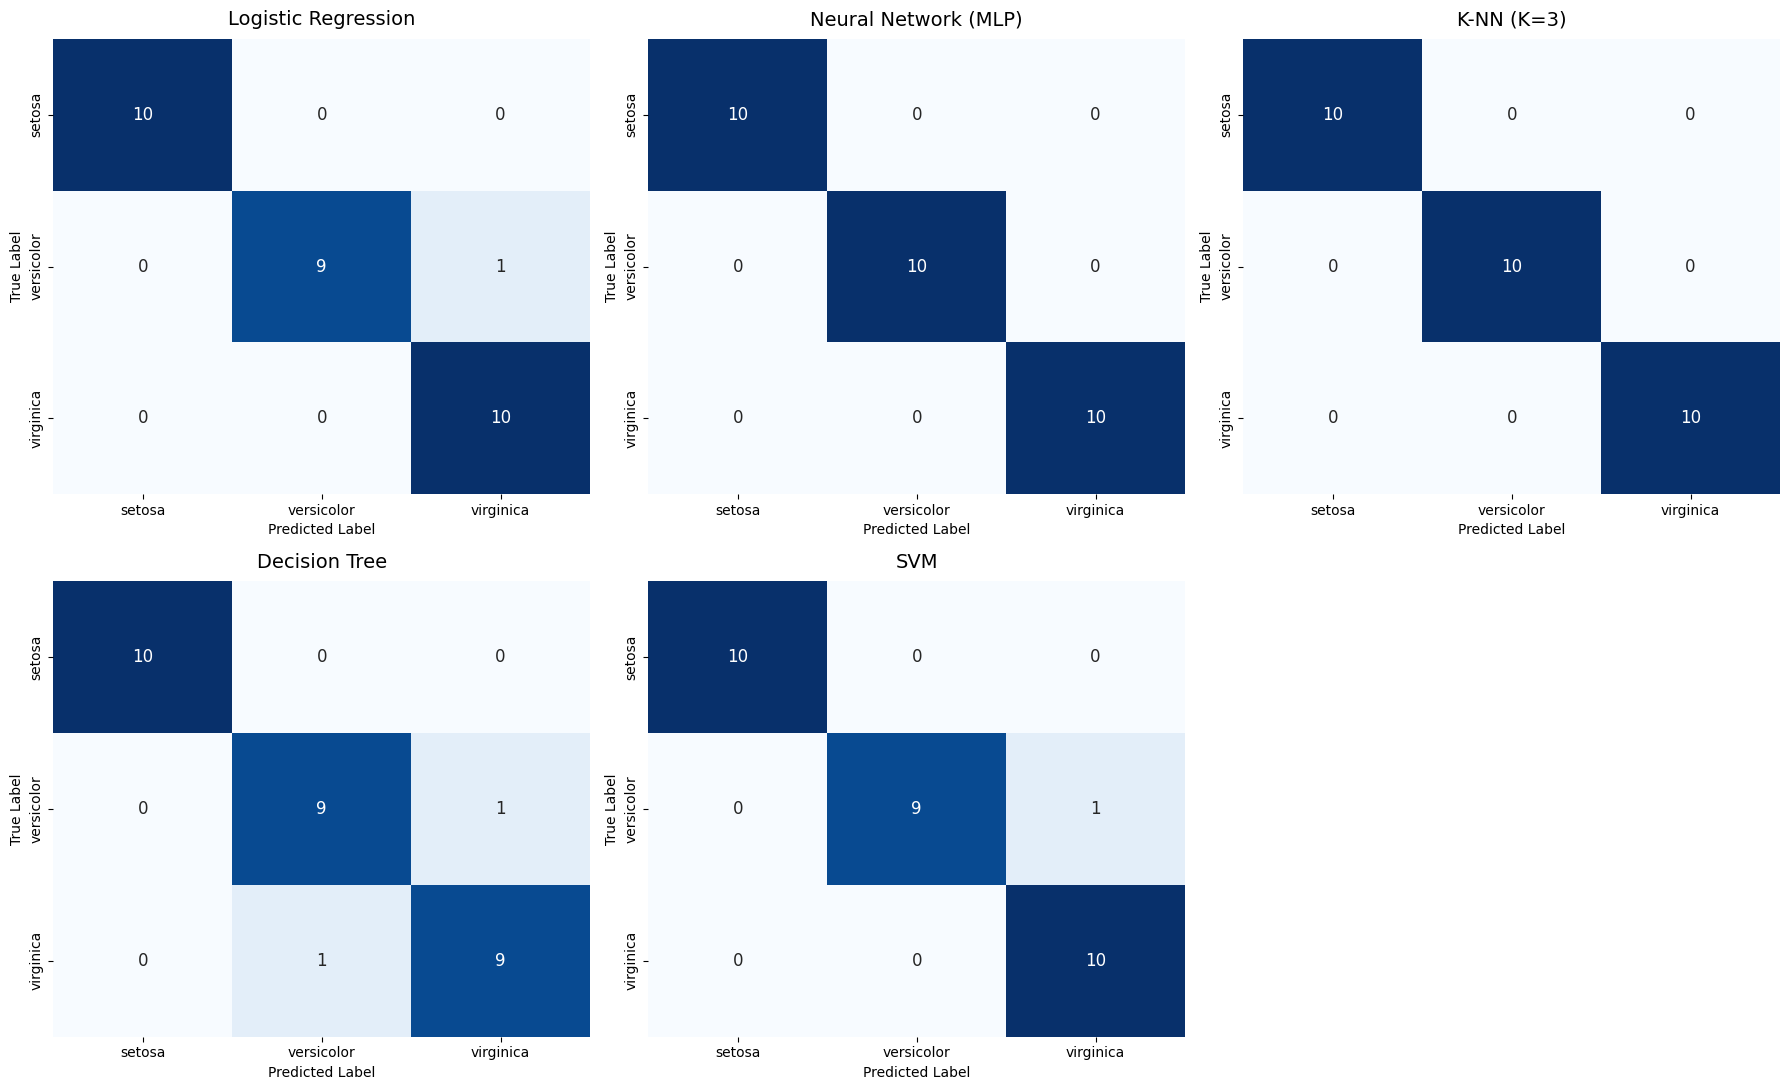

In [31]:
import seaborn as sns

classifiers = {
    "Logistic Regression": LogisticRegression(max_iter=200),
    "Neural Network (MLP)": MLPClassifier(hidden_layer_sizes=(16, 8), max_iter=1000, random_state=42),
    "K-NN (K=3)": KNeighborsClassifier(n_neighbors=3),
    "Decision Tree": DecisionTreeClassifier(max_depth=4, random_state=42),
    "SVM": SVC(probability=True, random_state=42)
}

fig, axes = plt.subplots(2, 3, figsize=(18, 11))
axes = axes.ravel()

for idx, (name, clf) in enumerate(classifiers.items()):
    clf.fit(X_train, Y_train)
    preds = clf.predict(X_test)
    cm_visual = confusion_matrix(Y_test, preds)

    ax = axes[idx]
    sns.heatmap(cm_visual, annot=True, fmt='d', cmap='Blues', cbar=False,
                xticklabels=iris.target_names, yticklabels=iris.target_names, ax=ax, annot_kws={"size": 12})
    ax.set_title(f"{name}", fontsize=14, pad=10)
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("True Label")

# Turn off the empty subplot
fig.delaxes(axes[-1])
plt.tight_layout()
plt.show()

## **Clustering Models (Practicals 11 - 12)**

In [28]:
# 11. K-means Clustering
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score

kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
kmeans_labels = kmeans.fit_predict(X)

print("=== 11. K-means Clustering ===")
print(f"Silhouette Score: {silhouette_score(X, kmeans_labels):.4f}")
print(f"Davies-Bouldin Index: {davies_bouldin_score(X, kmeans_labels):.4f}")

=== 11. K-means Clustering ===
Silhouette Score: 0.5528
Davies-Bouldin Index: 0.6620


In [29]:
# 12. Hierarchical Clustering (Agglomerative)
from sklearn.cluster import AgglomerativeClustering

hierarchical = AgglomerativeClustering(n_clusters=3)
hier_labels = hierarchical.fit_predict(X)

print("=== 12. Hierarchical Clustering ===")
print(f"Silhouette Score: {silhouette_score(X, hier_labels):.4f}")
print(f"Davies-Bouldin Index: {davies_bouldin_score(X, hier_labels):.4f}")

=== 12. Hierarchical Clustering ===
Silhouette Score: 0.5543
Davies-Bouldin Index: 0.6563


### **Visualizing Clustering Results (PCA 2D Space)**
Since the features are 4-dimensional, we can reduce them to 2 dimensions using Principal Component Analysis (PCA) to visualize clusters and boundaries.

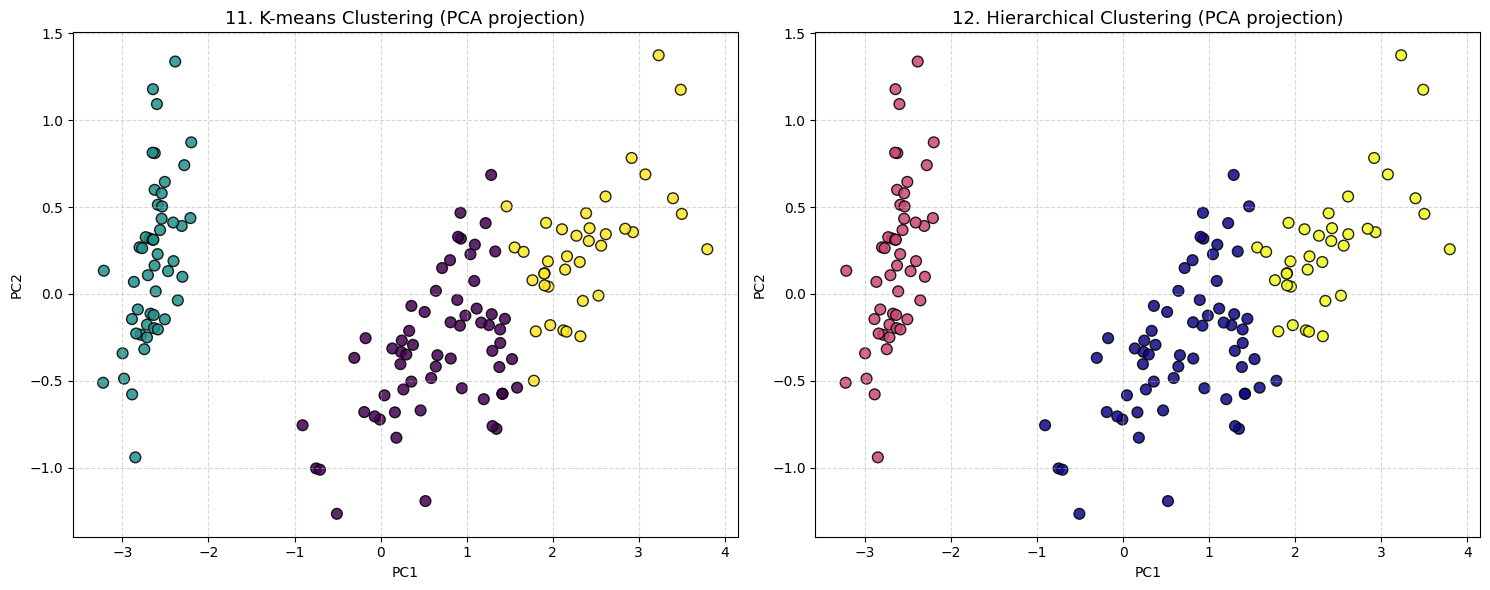

In [32]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# K-means Visual
ax1.scatter(X_pca[:, 0], X_pca[:, 1], c=kmeans_labels, cmap='viridis', s=60, edgecolors='k', alpha=0.85)
ax1.set_title("11. K-means Clustering (PCA projection)", fontsize=13)
ax1.set_xlabel("PC1")
ax1.set_ylabel("PC2")
ax1.grid(True, linestyle='--', alpha=0.5)

# Hierarchical Visual
ax2.scatter(X_pca[:, 0], X_pca[:, 1], c=hier_labels, cmap='plasma', s=60, edgecolors='k', alpha=0.85)
ax2.set_title("12. Hierarchical Clustering (PCA projection)", fontsize=13)
ax2.set_xlabel("PC1")
ax2.set_ylabel("PC2")
ax2.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()